In [1]:
#project starts-----

In [2]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 

import warnings

warnings.filterwarnings('ignore')

In [3]:
df= pd.read_csv('quikr_car (1).csv')

In [4]:
df.head()

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
2,Maruti Suzuki Alto 800 Vxi,Maruti,2018,Ask For Price,"22,000 kms",Petrol
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,"3,25,000","28,000 kms",Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,"5,75,000","36,000 kms",Diesel


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 892 entries, 0 to 891
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   name        892 non-null    str  
 1   company     892 non-null    str  
 2   year        892 non-null    str  
 3   Price       892 non-null    str  
 4   kms_driven  840 non-null    str  
 5   fuel_type   837 non-null    str  
dtypes: str(6)
memory usage: 92.3 KB


In [6]:
# eda and data - cleaning 

#year should be in correct datatype and has many errors 'd Ex', 'n...', 'e...', 'D...', ', Ac', 'go .', 'k...', 'o c4', 'zire',
#price should in correct dtype and 'Ask For Price'
#kms-driven null values remove or fill and too has errors  'Petrol' and should in int 
#full_type 
#fuel_type has null values 

In [7]:
df_copy = df.copy()

In [8]:
df_copy

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
2,Maruti Suzuki Alto 800 Vxi,Maruti,2018,Ask For Price,"22,000 kms",Petrol
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,"3,25,000","28,000 kms",Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,"5,75,000","36,000 kms",Diesel
...,...,...,...,...,...,...
887,Ta,Tara,zest,"3,10,000",NaN,NaN
888,Tata Zest XM Diesel,Tata,2018,"2,60,000","27,000 kms",Diesel
889,Mahindra Quanto C8,Mahindra,2013,"3,90,000","40,000 kms",Diesel
890,Honda Amaze 1.2 E i VTEC,Honda,2014,"1,80,000",Petrol,NaN


In [9]:
# data is too inconsistent and has lots of errors
df_copy.columns
df_copy['Price'].unique()
df_copy['name'].unique()
df_copy['company'].unique() # some errors 
df_copy['year'].unique() # errors 
df_copy['kms_driven'].unique() 
df_copy['fuel_type'].unique() 

<ArrowStringArray>
['Petrol', 'Diesel', nan, 'LPG']
Length: 4, dtype: str

In [10]:
#year 
df_copy['year'] = pd.to_numeric(df_copy['year'], errors='coerce')
df_copy.dropna(subset=['year'], inplace=True)

In [11]:
df_copy['year'].value_counts()

year
2015.0    117
2014.0     94
2013.0     94
2016.0     76
2012.0     75
2011.0     60
2017.0     56
2009.0     56
2010.0     44
2018.0     34
2006.0     22
2019.0     22
2007.0     19
2008.0     16
2005.0     13
2003.0     13
2004.0     12
2000.0      7
2002.0      5
2001.0      5
1995.0      2
Name: count, dtype: int64

In [12]:
#Price has Ask for Price

# Remove commas from prices
df_copy['Price'] = df_copy['Price'].str.replace(',', '', regex=False)
# Convert prices into numeric values
df_copy['Price'] = pd.to_numeric(df_copy['Price'], errors='coerce')
# Remove rows where price is unavailable
df_copy.dropna(subset=['Price'], inplace=True)

print(df_copy.shape)
print(df_copy['Price'].head())

(819, 6)
0     80000.0
1    425000.0
3    325000.0
4    575000.0
6    175000.0
Name: Price, dtype: float64


In [13]:
# kms_driven has object values with kms at last.
df_copy['kms_driven'].value_counts()

#45,000 kms

def remove_kms(s):
    n = len(s)
    slice = -1
    for i in range(n):
        if s[i] == " ":
            slice = i
    return s[0:slice]


df_copy['kms_driven'] = df_copy['kms_driven'].apply(remove_kms)
df_copy['kms_driven'] = df_copy['kms_driven'].str.replace(',', '', regex=False)
df_copy['kms_driven'] = pd.to_numeric(df_copy['kms_driven'], errors='coerce')
df_copy.dropna(subset=['kms_driven'], inplace=True)

In [14]:
#fuel_type has nan values
df_copy.dropna(subset=['fuel_type'],inplace=True)
df_copy['fuel_type'].value_counts()

fuel_type
Petrol    428
Diesel    386
LPG         2
Name: count, dtype: int64

In [15]:
# duplicated rows remove 

df_copy.duplicated().sum()
df_copy.drop_duplicates(inplace=True)

In [16]:
df_copy.info()

<class 'pandas.DataFrame'>
Index: 724 entries, 0 to 889
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   name        724 non-null    str    
 1   company     724 non-null    str    
 2   year        724 non-null    float64
 3   Price       724 non-null    float64
 4   kms_driven  724 non-null    float64
 5   fuel_type   724 non-null    str    
dtypes: float64(3), str(3)
memory usage: 65.8 KB


In [17]:
#name and company had spammed data...but with the previous cleaning, those rows got removed. Company does not need any cleaning now. Changing car names. Keeping only the first three words

In [18]:
def car_name(name):
    return ' '.join(name.split()[:3])

df_copy['name'] = df_copy['name'].apply(car_name)

In [19]:

df_copy.reset_index(drop=True, inplace=True)
df_copy.head()
df_copy.shape


(724, 6)

In [20]:
#Cleaned Data
df_copy

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing,Hyundai,2007.0,80000.0,45000.0,Petrol
1,Mahindra Jeep CL550,Mahindra,2006.0,425000.0,40.0,Diesel
2,Hyundai Grand i10,Hyundai,2014.0,325000.0,28000.0,Petrol
3,Ford EcoSport Titanium,Ford,2014.0,575000.0,36000.0,Diesel
4,Ford Figo,Ford,2012.0,175000.0,41000.0,Diesel
...,...,...,...,...,...,...
719,Maruti Suzuki Ritz,Maruti,2011.0,270000.0,50000.0,Petrol
720,Tata Indica V2,Tata,2009.0,110000.0,30000.0,Diesel
721,Toyota Corolla Altis,Toyota,2009.0,300000.0,132000.0,Petrol
722,Tata Zest XM,Tata,2018.0,260000.0,27000.0,Diesel


In [21]:

df_copy['year'] = df_copy['year'].astype(int)
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 724 entries, 0 to 723
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   name        724 non-null    str    
 1   company     724 non-null    str    
 2   year        724 non-null    int64  
 3   Price       724 non-null    float64
 4   kms_driven  724 non-null    float64
 5   fuel_type   724 non-null    str    
dtypes: float64(2), int64(1), str(3)
memory usage: 55.0 KB


In [22]:
df_copy.describe()

,year,Price,kms_driven
count,724.000000,7.240000e+02,724.000000
mean,2012.321823,4.032451e+05,46791.342541
std,4.122940,4.802936e+05,34575.416435
min,1995.000000,3.000000e+04,0.000000
25%,2010.000000,1.650000e+05,27000.000000
50%,2013.000000,2.900000e+05,42000.000000
75%,2015.000000,4.899990e+05,59000.000000
max,2019.000000,8.500003e+06,400000.000000


In [23]:
df_copy = df_copy[df_copy['Price'] <= 6000000]

df_copy.reset_index(drop=True, inplace=True)

In [24]:
df_copy

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing,Hyundai,2007,80000.0,45000.0,Petrol
1,Mahindra Jeep CL550,Mahindra,2006,425000.0,40.0,Diesel
2,Hyundai Grand i10,Hyundai,2014,325000.0,28000.0,Petrol
3,Ford EcoSport Titanium,Ford,2014,575000.0,36000.0,Diesel
4,Ford Figo,Ford,2012,175000.0,41000.0,Diesel
...,...,...,...,...,...,...
718,Maruti Suzuki Ritz,Maruti,2011,270000.0,50000.0,Petrol
719,Tata Indica V2,Tata,2009,110000.0,30000.0,Diesel
720,Toyota Corolla Altis,Toyota,2009,300000.0,132000.0,Petrol
721,Tata Zest XM,Tata,2018,260000.0,27000.0,Diesel


In [25]:
df_copy.to_csv('Cleaned_Car_data.csv')

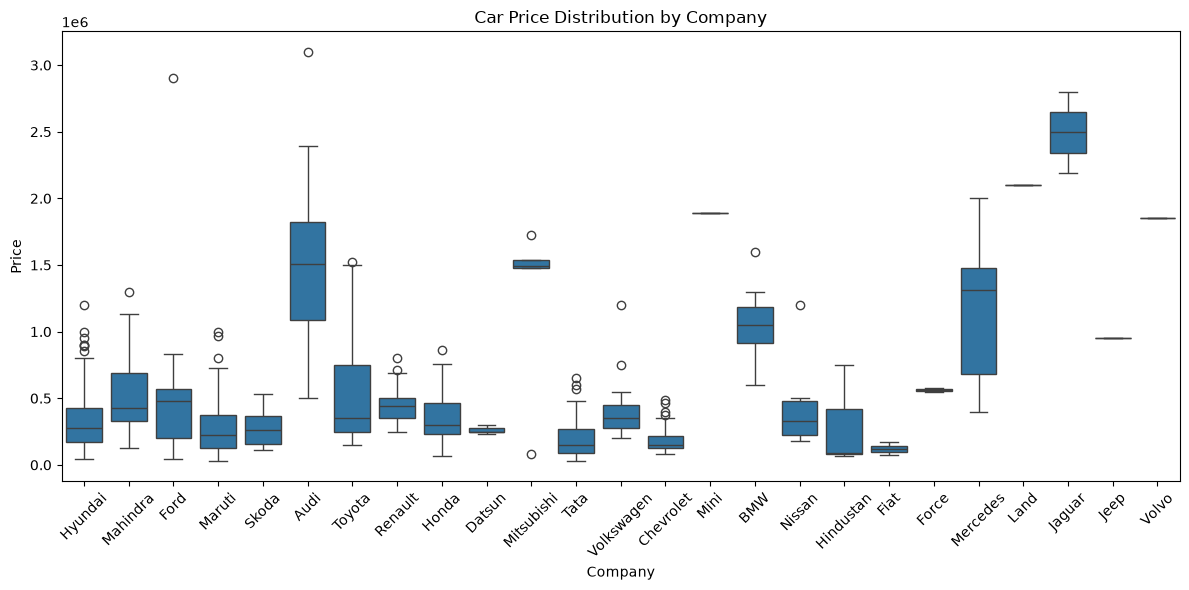

In [26]:
# Checking relationship of Company with Price

plt.figure(figsize=(12, 6))

sns.boxplot(data=df_copy, x='company', y='Price')
plt.xticks(rotation=45)
plt.title('Car Price Distribution by Company')
plt.xlabel('Company')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

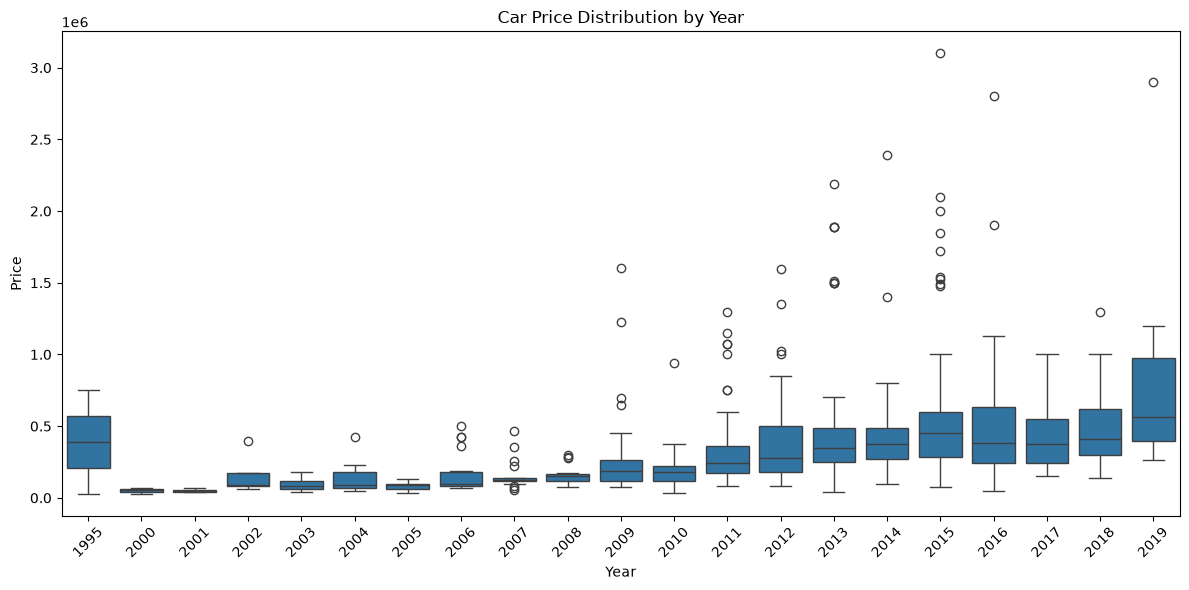

In [27]:
#Checking relationship of Year with Price

plt.figure(figsize=(12, 6))

sns.boxplot(data=df_copy, x='year', y='Price')

plt.xticks(rotation=45)
plt.title('Car Price Distribution by Year')
plt.xlabel('Year')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

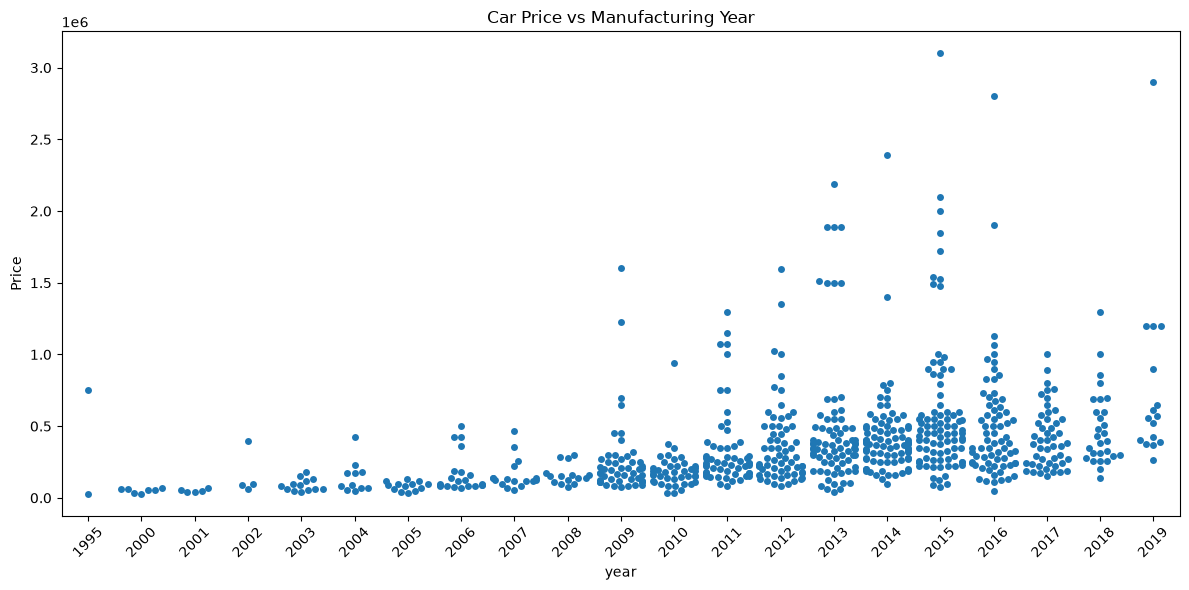

In [28]:
plt.figure(figsize=(12, 6))
sns.swarmplot(data=df_copy, x='year', y='Price')
plt.xticks(rotation=45)
plt.title('Car Price vs Manufacturing Year')
plt.tight_layout()
plt.show()

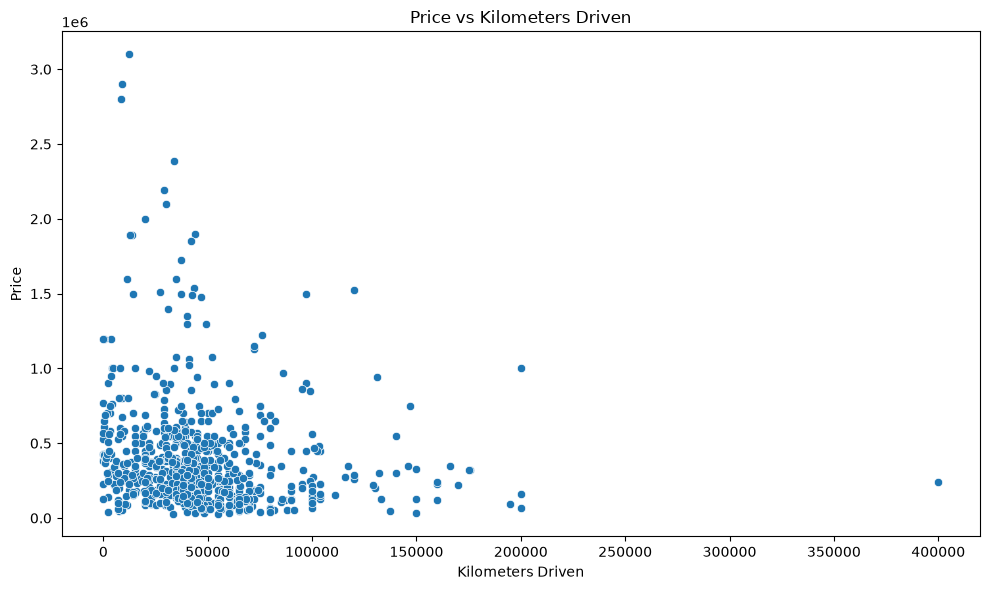

In [29]:
#Checking relationship of kms_driven with Price

plt.figure(figsize=(10, 6))

sns.scatterplot(data=df_copy, x='kms_driven', y='Price')

plt.title('Price vs Kilometers Driven')
plt.xlabel('Kilometers Driven')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

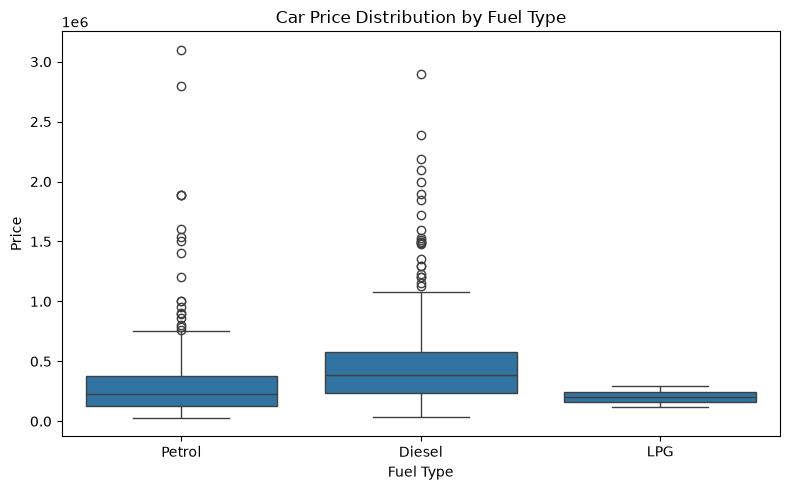

In [30]:
# Checking relationship of Fuel Type with Price

plt.figure(figsize=(8, 5))

sns.boxplot(data=df_copy, x='fuel_type', y='Price')

plt.title('Car Price Distribution by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

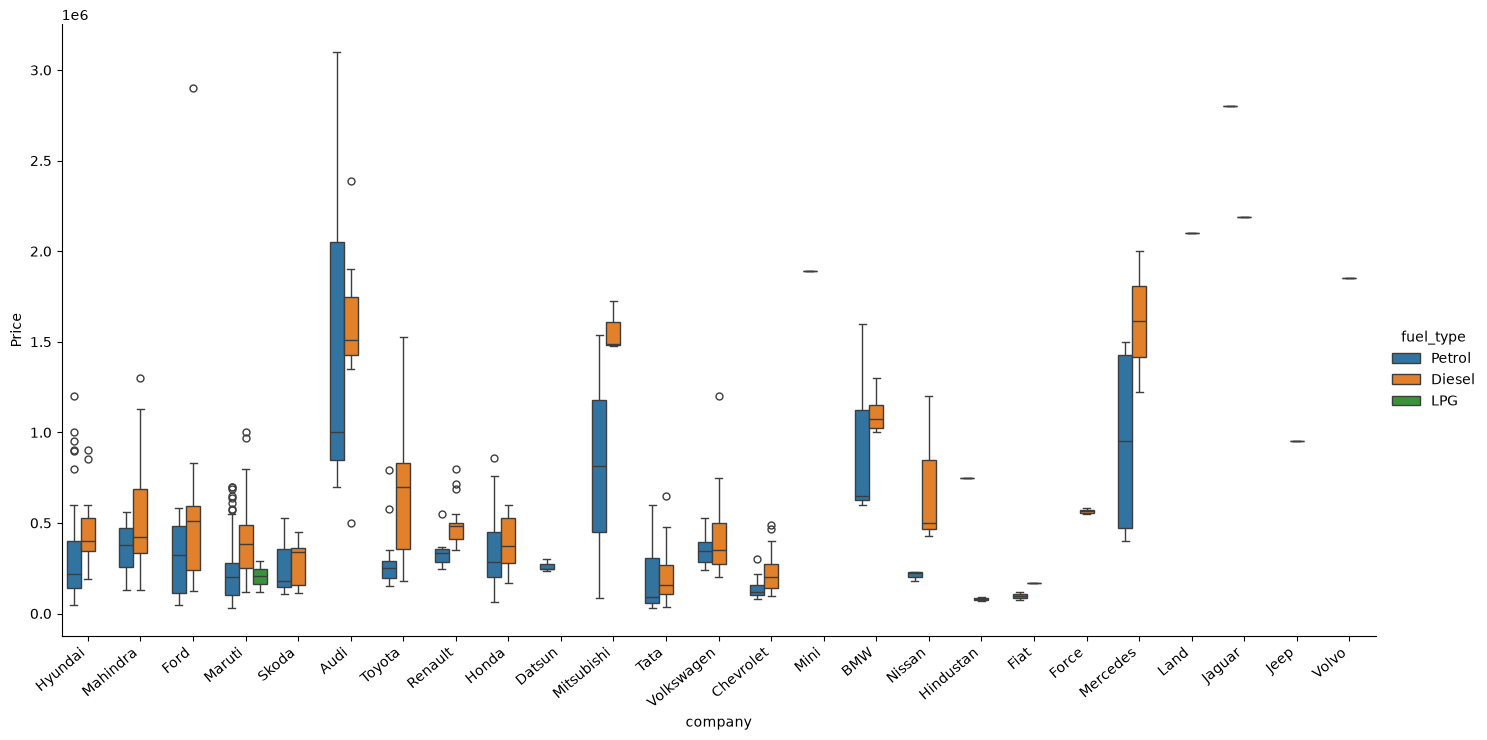

In [31]:
# Relationship of Price with FuelType, Year and Company mixed
g = sns.catplot(
    data=df_copy,
    x='company',
    y='Price',
    hue='fuel_type',
    kind='box',
    height=7,
    aspect=2
)

g.set_xticklabels(rotation=40, ha='right')
plt.show()

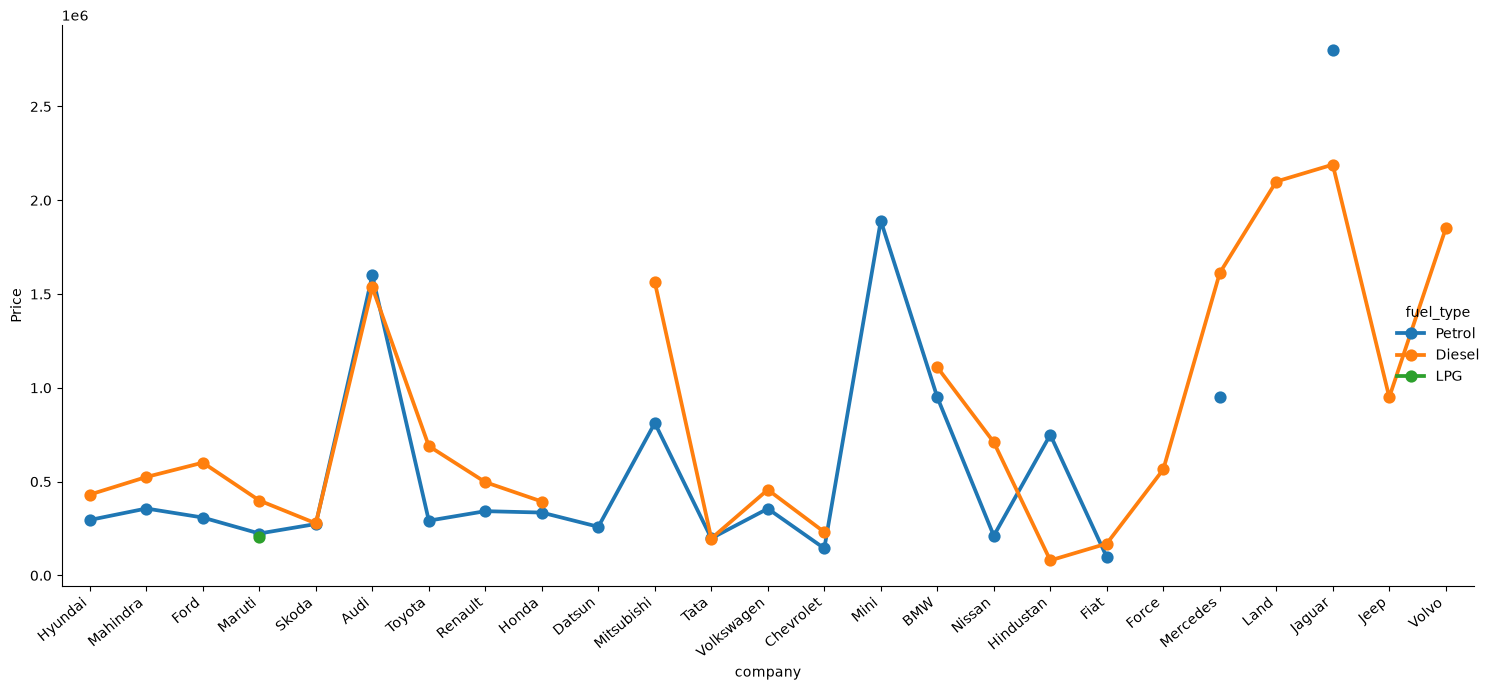

In [32]:
sns.catplot(
    data=df_copy,
    x='company',
    y='Price',
    hue='fuel_type',
    kind='point',
    height=7,
    aspect=2,
    errorbar=None
)

plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

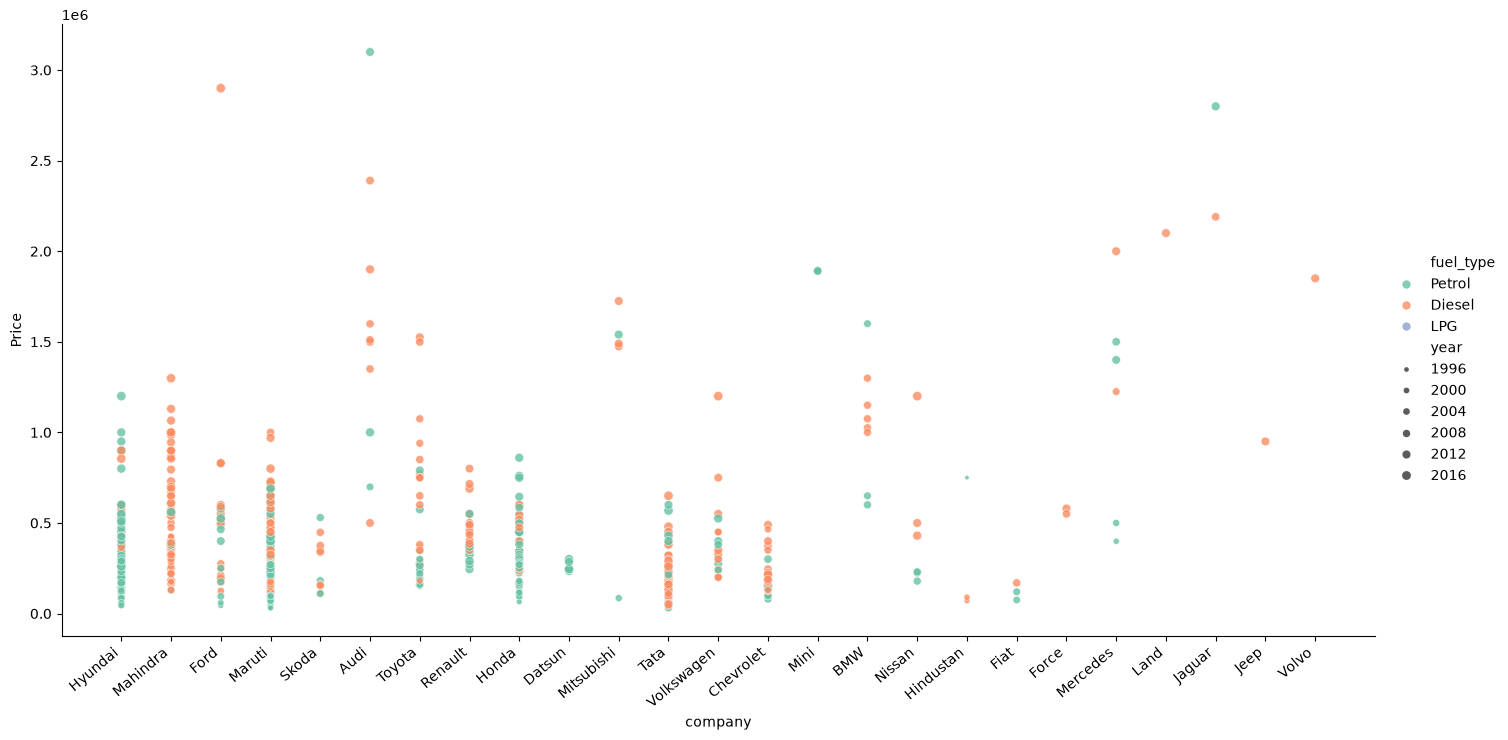

In [33]:
ax = sns.relplot(
    x='company',
    y='Price',
    data=df_copy,
    hue='fuel_type',
    size='year',
    height=7,
    aspect=2,
    sizes=(10, 45),
    palette='Set2',
    alpha=0.8
)

ax.set_xticklabels(rotation=40, ha='right')

In [34]:
# feature engineering


<class 'pandas.DataFrame'>
RangeIndex: 723 entries, 0 to 722
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   name        723 non-null    str    
 1   company     723 non-null    str    
 2   year        723 non-null    int64  
 3   Price       723 non-null    float64
 4   kms_driven  723 non-null    float64
 5   fuel_type   723 non-null    str    
dtypes: float64(2), int64(1), str(3)
memory usage: 34.0 KB


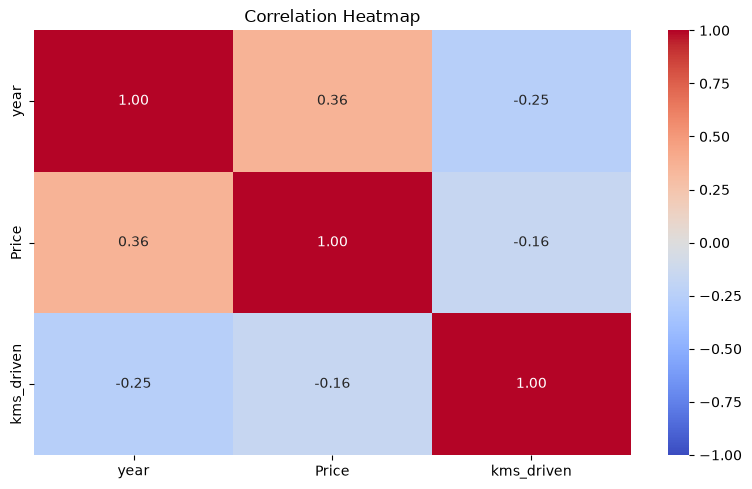

In [35]:
df_copy.columns
df_copy.info()
# all seem correlated , we can explore and make bins 

plt.figure(figsize=(8, 5))

sns.heatmap(
    df_copy.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [36]:
df_copy.shape
df_copy.head()

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing,Hyundai,2007,80000.0,45000.0,Petrol
1,Mahindra Jeep CL550,Mahindra,2006,425000.0,40.0,Diesel
2,Hyundai Grand i10,Hyundai,2014,325000.0,28000.0,Petrol
3,Ford EcoSport Titanium,Ford,2014,575000.0,36000.0,Diesel
4,Ford Figo,Ford,2012,175000.0,41000.0,Diesel


In [38]:
df_copy.shape


(723, 6)

In [26]:
df_copy = df_copy[df_copy['Price'] <= 2500000].copy()

In [40]:
df_copy

,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing,Hyundai,2007,80000.0,45000.0,Petrol
1,Mahindra Jeep CL550,Mahindra,2006,425000.0,40.0,Diesel
2,Hyundai Grand i10,Hyundai,2014,325000.0,28000.0,Petrol
3,Ford EcoSport Titanium,Ford,2014,575000.0,36000.0,Diesel
4,Ford Figo,Ford,2012,175000.0,41000.0,Diesel
...,...,...,...,...,...,...
718,Maruti Suzuki Ritz,Maruti,2011,270000.0,50000.0,Petrol
719,Tata Indica V2,Tata,2009,110000.0,30000.0,Diesel
720,Toyota Corolla Altis,Toyota,2009,300000.0,132000.0,Petrol
721,Tata Zest XM,Tata,2018,260000.0,27000.0,Diesel


In [27]:
## again doing final work

# ---------- 1. remove 3 extreme-price listings ----------

df_copy = df_copy[df_copy['Price'] < 2_500_000].reset_index(drop=True)

In [28]:
# ---------- 2. Feature engineering / extraction / binning ----------
CURRENT_YEAR = 2019
LUXURY = {'Audi', 'Mercedes', 'BMW', 'Jaguar', 'Land', 'Mini', 'Volvo', 'Porsche'}

def add_features(df):
    df = df.copy()
    df['age']          = CURRENT_YEAR - df['year']
    df['log_kms']      = np.log1p(df['kms_driven'])
    df['kms_per_year'] = df['kms_driven'] / df['age'].clip(lower=1)
    df['brand_model']  = df['name'].str.split().str[:2].str.join(' ')
    df['luxury']       = df['company'].isin(LUXURY).astype(int)
    df['age_x_lux']    = df['age'] * df['luxury']
    df['dep']          = np.exp(-0.12 * df['age'])
    df['dep_x_lux']    = df['dep'] * df['luxury']
    df['kms_bin']      = pd.cut(df['kms_driven'], [-1, 20000, 40000, 60000, 90000, 1e7], labels=False)
    df['low_kms']      = (df['kms_driven'] < 5000).astype(int)
    df['age2']         = df['age'] ** 2
    df['age_x_kms']    = df['age'] * df['log_kms']
    return df

df_copy = add_features(df_copy)

cats = ['company', 'fuel_type', 'brand_model']
nums = ['age', 'log_kms', 'kms_per_year', 'luxury', 'age_x_lux', 'dep',
        'dep_x_lux', 'kms_bin', 'low_kms', 'age2', 'age_x_kms']

X = df_copy[cats + nums]
y = df_copy['Price']


In [43]:
# Pearson Correlation with Price
correlation = df_copy[nums + ['Price']].corr(method='pearson')['Price']

correlation = correlation.sort_values(ascending=False).round(3)

print("Feature Correlation with Price:\n")
print(correlation)

Feature Correlation with Price:

Price           1.000
dep_x_lux       0.629
luxury          0.600
age_x_lux       0.470
dep             0.356
low_kms         0.128
kms_per_year    0.050
log_kms        -0.148
kms_bin        -0.167
age2           -0.344
age            -0.373
age_x_kms      -0.374
Name: Price, dtype: float64


In [ ]:
# ---------- 3. Scaling + encoding + LinearRegression ----------

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cats),
    ('num', StandardScaler(), nums)
])

Pipeline([
    ('pre', pre),
    ('lr', LinearRegression())
])

# named (picklable) functions instead of lambdas for the target transform
def price_transform(y):
    return np.power(y, 0.4)

def price_inverse_transform(y):
    return np.power(np.clip(y, 0, None), 2.5)

model = TransformedTargetRegressor(
    regressor=Pipeline([
        ('pre', pre),
        ('lr', LinearRegression())
    ]),
    func=price_transform,
    inverse_func=price_inverse_transform
)

In [30]:
# ---------- 4. Evaluation ----------

from sklearn.model_selection import RepeatedKFold
from sklearn.model_selection import cross_val_score

cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=0)

scores = cross_val_score(model, X, y, cv=cv, scoring='r2')

# Split Data into Training and Testing Sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Train the Model
model.fit(X_train, y_train)

# Make Predictions
y_pred = model.predict(X_test)


In [31]:
# Import Evaluation Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np


# Calculate Evaluation Metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display Results
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("Hold-out R² Score:", round(r2_score(y_test, y_pred), 3))
print(f'CV R2: {scores.mean():.3f} ± {scores.std():.3f}')


MAE: 97527.23
MSE: 28346393250.5
RMSE: 168363.87
Hold-out R² Score: 0.724
CV R2: 0.783 ± 0.061


In [32]:
# ---------- 5. Train on all data & save ----------
import pickle

model.fit(X, y)
pickle.dump(model, open('LinearRegressionModel.pkl', 'wb'))

PicklingError: Can't pickle <function <lambda> at 0x0000014BDEEBA2A0>: it's not found as __main__.<lambda>

In [33]:
# ---------- 6. Predict ----------
def predict_price(name, company, year, kms_driven, fuel_type):
    r = pd.DataFrame([dict(name=name, company=company, year=year,
                           kms_driven=kms_driven, fuel_type=fuel_type)])
    return model.predict(add_features(r)[cats + nums])[0]

print(f" Rs. {predict_price('Maruti Suzuki Swift', 'Maruti', 2019, 100, 'Petrol')}")

 Rs. 451846.3974251521


In [34]:
df_copy.to_csv('car_data_final.csv', index=False)